# 04 · Final evaluation on the held-out test set, and the economics

This is the **first and only** time the test set's outcomes are used. Nothing here is tuned or chosen after looking at these numbers (the uplift tree's settings and the 'deployment candidate' were fixed in notebook 03 on training data only).

**How can we evaluate uplift if we never see both outcomes for the same person?** We evaluate *rankings*. Take the customers a model ranks highest; inside that group, compare those who randomly got the email with those who randomly did not. Because assignment was random, the difference is an unbiased estimate of that group's uplift. A good model puts high-uplift customers at the top.

Strategies compared: **Random**, **Propensity** (classic 'likely visitor' model), **T-learner** (main uplift model), **X-learner**, **S-learner**, **Uplift tree** (honest, interpretable). Primary outcome: visit. Then three business questions: *who* to contact, *which* email version, and *when targeting pays* (economics).

In [28]:
# Make `src` importable from the notebooks folder (works on Windows and macOS)
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import *
FIG_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_json(obj, name):
    (RESULTS_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

In [29]:
from src.evaluation import (uplift_curves, qini_coefficient, auuc, uplift_at_k, share_of_lift_at_k, uplift_by_decile, diff_in_means,
                            bootstrap, bootstrap_diff, policy_incremental_at_k, bootstrap_policy, bootstrap_policy_diff)
from src.simulation import (strategy_table, add_economics, best_threshold, K_GRID, value_per_visit, add_visit_economics,
                            break_even_cost, decision_map)
from src.preprocessing import make_split
from scipy.stats import spearmanr

v = pd.read_csv(
    PROCESSED_DIR / "validation_scores.csv",
    index_col="customer_id"
)
s = pd.read_csv(
    PROCESSED_DIR / "test_scores.csv",
    index_col="customer_id"
)

train, validation, test = make_split()
print("Validation customers:", len(v))
print("Testing customers:", len(s))

MODELS = {"Random": "random_score", "Propensity": "propensity", "T-learner": "T_uplift_{arm}",
          "X-learner": "X_uplift_{arm}", "S-learner": "S_uplift_{arm}", "Uplift tree": "UT_uplift_{arm}"}
COL = {"Random": "#9CA3AF", "Propensity": "#D97706", "T-learner": "#0F766E", "X-learner": "#7C3AED", "S-learner": "#64748B", "Uplift tree": "#DC2626"}
POP = 64_000   # we report money for a customer base the size of the whole Hillstrom file
print(len(s), "test customers;", s.arm.value_counts().sort_index().to_dict())

Validation customers: 12800
Testing customers: 12800
12800 test customers; {0: 4261, 1: 4261, 2: 4278}


## 1. Ranking quality per email (outcome = visit)
For each email separately (men's vs control, women's vs control):
* **Qini coefficient**: area between the model's Qini curve and the random line (0 = random).
* **AUUC**: area under the uplift curve minus the random line (0 = random).
* **uplift@K**: observed extra visit rate in the top K% (treated rate − control rate).

All with 95% bootstrap CIs (300 resamples within arm).

In [30]:
def arm_data(arm, outcome="visit"):
    sub = s[s.arm.isin([0, arm])]
    return sub, sub[outcome].to_numpy(), (sub.arm == arm).astype(int).to_numpy()

rows, curves = [], {}
for arm in (1, 2):
    sub, y, t = arm_data(arm)
    for name, col in MODELS.items():
        model_scores = sub[col.format(arm=ARM_SHORT[arm])].to_numpy()
        curves[(arm, name)] = uplift_curves(y, t, model_scores)
        r = {"email": ARMS[arm], "model": name}
        for mname, fn, kw in [("qini", qini_coefficient, {}), ("auuc", auuc, {}),
                              ("uplift@10%", uplift_at_k, {"k": .1}), ("uplift@20%", uplift_at_k, {"k": .2}), ("uplift@30%", uplift_at_k, {"k": .3})]:
            b = bootstrap(fn, y, t, model_scores, n_boot=N_BOOT, **kw)
            r[mname], r[mname + "_lo"], r[mname + "_hi"] = b["estimate"], b["lo"], b["hi"]
        rows.append(r)
rank = pd.DataFrame(rows)
display(rank[["email", "model", "qini", "qini_lo", "qini_hi", "auuc", "uplift@10%", "uplift@10%_lo", "uplift@10%_hi", "uplift@30%"]])

,email,model,qini,qini_lo,qini_hi,auuc,uplift@10%,uplift@10%_lo,uplift@10%_hi,uplift@30%
0,Mens E-Mail,Random,-0.0003,-0.0023,0.0020,-0.0009,0.0732,0.0312,0.1151,0.0789
1,Mens E-Mail,Propensity,0.0023,-0.0001,0.0044,0.0048,0.1388,0.0806,0.2004,0.1020
2,Mens E-Mail,T-learner,0.0002,-0.0022,0.0023,0.0005,0.0809,0.0274,0.1312,0.0751
3,Mens E-Mail,X-learner,-0.0011,-0.0036,0.0010,-0.0021,0.0681,0.0195,0.1250,0.0629
4,Mens E-Mail,S-learner,0.0002,-0.0021,0.0024,0.0004,0.1138,0.0584,0.1715,0.0759
5,Mens E-Mail,Uplift tree,0.0016,-0.0012,0.0035,0.0032,0.0942,0.0522,0.1647,0.0984
6,Womens E-Mail,Random,-0.0010,-0.0028,0.0010,-0.0020,0.0284,-0.0112,0.0687,0.0443
7,Womens E-Mail,Propensity,0.0024,0.0005,0.0043,0.0052,0.0941,0.0404,0.1501,0.0655
8,Womens E-Mail,T-learner,0.0037,0.0016,0.0060,0.0081,0.0885,0.0425,0.1381,0.0832
9,Womens E-Mail,X-learner,0.0036,0.0015,0.0056,0.0077,0.0968,0.0516,0.1456,0.0712


### Business reading: how much of the campaign's effect do we keep if we contact only part of the base?
The Qini coefficient is hard to feel. Two numbers marketers understand:
* **Share of lift captured** = incremental visits obtained by contacting the top K% ÷ incremental visits from contacting everyone. Random targeting keeps K% of the lift; a perfect ranking keeps 100% once all persuadables are in.
* **Cost per incremental visit** at the scenario cost per contact ($0.15): contacts needed per extra visit × cost.

In [31]:
lift_rows = []
for arm in (1, 2):
    sub, y, t = arm_data(arm)
    ate_arm = y[t == 1].mean() - y[t == 0].mean()
    lift_rows.append({"email": ARMS[arm], "model": "Everyone", "k": 1.0, "share_of_lift": 1.0, "uplift_in_group": ate_arm,
                      "cost_per_inc_visit": COST_PER_CONTACT / ate_arm})
    for name in ("Random", "Propensity", "T-learner", "Uplift tree"):
        model_scores = sub[MODELS[name].format(arm=ARM_SHORT[arm])].to_numpy()
        for k in (0.3, 0.5):
            share = k if name == "Random" else share_of_lift_at_k(y, t, model_scores, k)
            u = ate_arm if name == "Random" else uplift_at_k(y, t, model_scores, k)
            lift_rows.append({"email": ARMS[arm], "model": name, "k": k, "share_of_lift": share, "uplift_in_group": u,
                              "cost_per_inc_visit": COST_PER_CONTACT / u if u > 0 else np.nan})
lift = pd.DataFrame(lift_rows)
show = lift.assign(share_of_lift=lambda d: (d.share_of_lift * 100).round(0).astype(int).astype(str) + "%",
                   uplift_in_group=lambda d: (d.uplift_in_group * 100).round(1), cost_per_inc_visit=lambda d: d.cost_per_inc_visit.round(2))
display(show[show.email == "Womens E-Mail"].set_index(["model", "k"]).drop(columns="email"))
display(show[show.email == "Mens E-Mail"].set_index(["model", "k"]).drop(columns="email"))

share_of_lift  uplift_in_group  cost_per_inc_visit
model       k                                                        
Everyone    1.0000          100%           4.5000              3.3000
Random      0.3000           30%           4.5000              3.3000
            0.5000           50%           4.5000              3.3000
Propensity  0.3000           42%           6.5000              2.2900
            0.5000           65%           6.0000              2.5000
T-learner   0.3000           53%           8.3000              1.8000
            0.5000           79%           7.4000              2.0400
Uplift tree 0.3000           56%           8.7000              1.7300
            0.5000           82%           7.6000              1.9600

share_of_lift  uplift_in_group  cost_per_inc_visit
model       k                                                        
Everyone    1.0000          100%           7.7000              1.9500
Random      0.3000           30%           7.7000              1.9500
            0.5000           50%           7.7000              1.9500
Propensity  0.3000           39%          10.2000              1.4700
            0.5000           58%           8.9000              1.6800
T-learner   0.3000           29%           7.5000              2.0000
            0.5000           46%           7.0000              2.1300
Uplift tree 0.3000           38%           9.8000              1.5200
            0.5000           54%           8.1000              1.8400

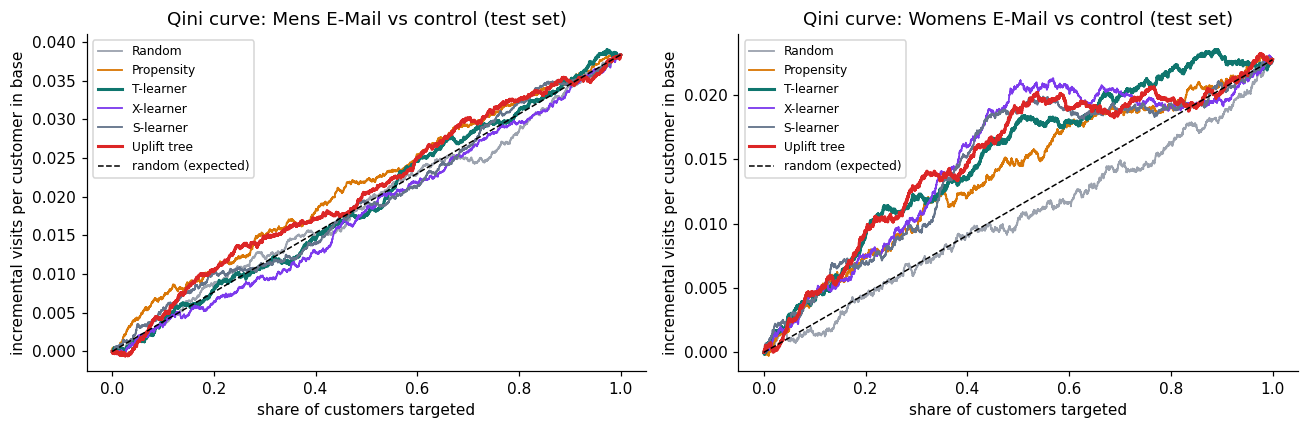

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, arm in zip(axes, (1, 2)):
    n = len(curves[(arm, "Random")]) - 1
    for name in MODELS:
        cur = curves[(arm, name)]
        ax.plot(cur.frac, cur.qini / n, label=name, color=COL[name], lw=2 if name in ("T-learner", "Uplift tree") else 1.2)
    end = curves[(arm, "Random")].qini.iloc[-1] / n
    ax.plot([0, 1], [0, end], ls="--", c="black", lw=1, label="random (expected)")
    ax.set_title(f"Qini curve: {ARMS[arm]} vs control (test set)"); ax.set_xlabel("share of customers targeted")
    ax.set_ylabel("incremental visits per customer in base"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_qini_curves.png", bbox_inches="tight"); plt.show()

## 2. Is the difference between models statistically convincing?
A **paired** bootstrap computes both models on the same resample, so the noise they share cancels out. If the 95% CI of the difference excludes 0, the gap is convincing. `p_a_better` = share of resamples where the first model wins.

In [33]:
pairs = [("T-learner", "Random"), ("T-learner", "Propensity"), ("X-learner", "T-learner"), ("X-learner", "Propensity"),
         ("S-learner", "T-learner"), ("Uplift tree", "T-learner"), ("Uplift tree", "Propensity"), ("Uplift tree", "Random"), ("Propensity", "Random")]
prow = []
for arm in (1, 2):
    sub, y, t = arm_data(arm)
    for a, b in pairs:
        sa, sb = (sub[MODELS[m].format(arm=ARM_SHORT[arm])].to_numpy() for m in (a, b))
        d = bootstrap_diff(qini_coefficient, y, t, sa, sb, n_boot=N_BOOT)
        prow.append({"email": ARMS[arm], "comparison": f"{a} - {b}", **d})
paired = pd.DataFrame(prow)
paired["convincing (CI excludes 0)"] = (paired.lo > 0) | (paired.hi < 0)
display(paired)

,email,comparison,diff,lo,hi,p_a_better,convincing (CI excludes 0)
0,Mens E-Mail,T-learner - Random,0.0005,-0.0028,0.0037,0.5900,False
1,Mens E-Mail,T-learner - Propensity,-0.0021,-0.0050,0.0005,0.0467,False
2,Mens E-Mail,X-learner - T-learner,-0.0013,-0.0029,0.0004,0.0700,False
3,Mens E-Mail,X-learner - Propensity,-0.0034,-0.0059,-0.0013,0.0067,True
4,Mens E-Mail,S-learner - T-learner,0.0000,-0.0019,0.0021,0.5567,False
5,Mens E-Mail,Uplift tree - T-learner,0.0014,-0.0022,0.0044,0.7400,False
6,Mens E-Mail,Uplift tree - Propensity,-0.0007,-0.0041,0.0019,0.2300,False
7,Mens E-Mail,Uplift tree - Random,0.0019,-0.0015,0.0044,0.8300,False
8,Mens E-Mail,Propensity - Random,0.0026,-0.0004,0.0053,0.9500,False
9,Womens E-Mail,T-learner - Random,0.0047,0.0019,0.0074,1.0000,True


## 3. Uplift by decile of the T-learner score (with 95% CIs)
Decile 1 = customers the T-learner thinks the email helps most. If the model works, uplift should fall from left to right. This is also our test for **sleeping dogs**: only if the lowest deciles show uplift significantly below zero (CI entirely below 0) would we claim the email hurts some customers.

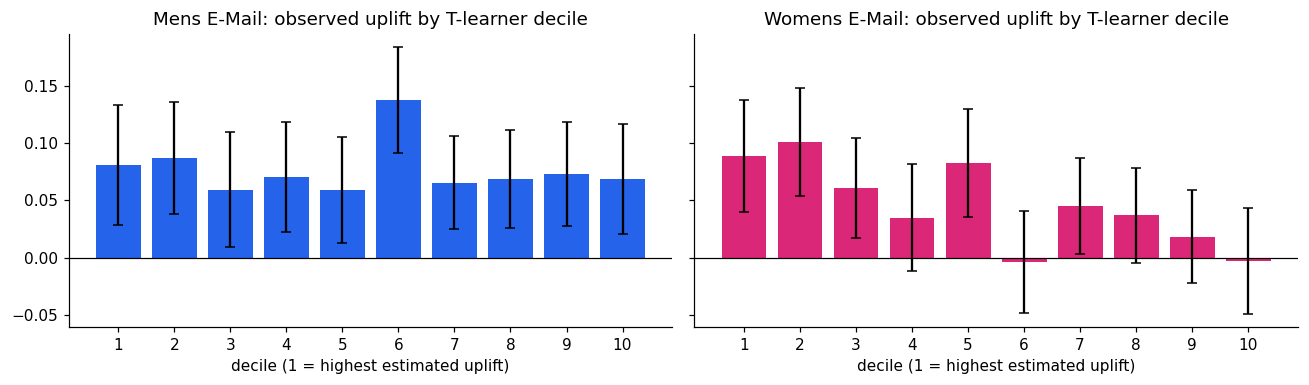

Mens E-Mail


,decile,n_treated,n_control,rate_treated,rate_control,uplift,ci_lo,ci_hi
0,1,395,458,0.2228,0.1419,0.0809,0.0288,0.1329
1,2,426,426,0.1995,0.1127,0.0869,0.0384,0.1353
2,3,431,421,0.1995,0.1401,0.0594,0.0091,0.1097
3,4,442,410,0.1878,0.1171,0.0707,0.0228,0.1187
4,5,436,416,0.1674,0.1082,0.0593,0.0132,0.1053
5,6,442,411,0.2127,0.0754,0.1372,0.0913,0.1832
6,7,417,435,0.1343,0.0690,0.0653,0.0248,0.1058
7,8,417,435,0.1487,0.0805,0.0682,0.0255,0.1109
8,9,433,419,0.1686,0.0955,0.0731,0.0280,0.1183
9,10,422,430,0.1872,0.1186,0.0686,0.0204,0.1168


Womens E-Mail


,decile,n_treated,n_control,rate_treated,rate_control,uplift,ci_lo,ci_hi
0,1,395,459,0.1975,0.1089,0.0885,0.0400,0.1371
1,2,423,431,0.1962,0.0951,0.1011,0.0541,0.1480
2,3,411,443,0.1509,0.0903,0.0606,0.0168,0.1043
3,4,406,448,0.1576,0.1228,0.0349,-0.0119,0.0816
4,5,443,411,0.1896,0.1071,0.0826,0.0353,0.1298
5,6,445,409,0.1236,0.1271,-0.0035,-0.0481,0.0410
6,7,430,424,0.1326,0.0873,0.0453,0.0034,0.0872
7,8,451,403,0.1264,0.0893,0.0371,-0.0044,0.0785
8,9,447,407,0.1119,0.0934,0.0185,-0.0222,0.0592
9,10,427,426,0.1358,0.1385,-0.0027,-0.0489,0.0436


Any decile with uplift significantly below zero (evidence of sleeping dogs)? {'mens': False, 'womens': False}
Womens E-Mail, uplift tree leaves: estimated (train) vs observed (test) uplift


,diff,se,lo,hi,n
leaf_uplift,,,,,
0.0741,0.0735,0.0104,0.0531,0.0940,"4,667.0000"
0.0122,0.0147,0.0098,-0.0045,0.0340,"3,872.0000"


In [34]:
dec = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, arm, col in zip(axes, (1, 2), ("#2563EB", "#DB2777")):
    sub, y, t = arm_data(arm)
    dec[arm] = uplift_by_decile(y, t, sub[f"T_uplift_{ARM_SHORT[arm]}"].to_numpy())
    d = dec[arm]
    ax.bar(d.decile, d.uplift, color=col, yerr=[d.uplift - d.ci_lo, d.ci_hi - d.uplift], capsize=3)
    ax.axhline(0, c="black", lw=0.8)
    ax.set_title(f"{ARMS[arm]}: observed uplift by T-learner decile"); ax.set_xlabel("decile (1 = highest estimated uplift)"); ax.set_xticks(range(1, 11))
plt.tight_layout(); plt.savefig(FIG_DIR / "04_uplift_deciles.png", bbox_inches="tight"); plt.show()
for arm in (1, 2):
    print(ARMS[arm]); display(dec[arm])
sleeping = {ARM_SHORT[a]: bool((dec[a].ci_hi < 0).any()) for a in (1, 2)}
print("Any decile with uplift significantly below zero (evidence of sleeping dogs)?", sleeping)

# the uplift tree has only a few distinct scores, so its natural unit is the leaf, not the decile
sub, y, t = arm_data(2)
leaf = pd.DataFrame({"y": y, "t": t, "leaf_uplift": sub["UT_uplift_womens"].round(4).to_numpy()})
leaf_tab = leaf.groupby("leaf_uplift").apply(lambda g: pd.Series({**diff_in_means(g.y[g.t == 1], g.y[g.t == 0]), "n": len(g)}), include_groups=False).sort_index(ascending=False)
print("Womens E-Mail, uplift tree leaves: estimated (train) vs observed (test) uplift"); display(leaf_tab)

## 4. The full campaign: choose WHO and WHICH email
Now each strategy targets the top K% of all test customers:
* **Uplift (T / X)**: rank by the best estimated uplift, send that customer's best email.
* **Propensity / Random**: rank by propensity / at random, send the email with the larger average effect on train (men's).

Estimate per targeted customer (no model assumptions): inside the top K%, customers who happened to receive the recommended email minus customers who received no email. 'Target everyone' is K = 100%.

For **Random** we use its *expected* result: a random K% has, on average, the same per-customer effect as everyone, so its value at every K equals the K = 100% estimate (a straight line in totals).

In [35]:
from src.simulation import add_visit_economics

VAL_STRATS = {
    "Random": (v.random_score, v.default_arm),
    "Propensity": (v.propensity, v.default_arm),
    "T-learner": (v.T_policy_score, v.T_best_arm),
    "X-learner": (v.X_policy_score, v.X_best_arm),
    "Uplift tree": (v.UT_policy_score, v.UT_best_arm),
}

val_table = strategy_table(
    v,
    VAL_STRATS,
    outcomes=("visit",),
)

visit_value = value_per_visit(train)["pooled"]

val_econ = add_visit_economics(
    val_table,
    population=64_000,
    value=visit_value,
    margin=MARGIN_RATE,
    cost=COST_PER_CONTACT,
)

val_best = best_threshold(val_econ)

display(
    val_best[
        ["strategy", "k", "n_contacted", "incremental_profit"]
    ]
)

SELECTED_K = dict(zip(val_best["strategy"], val_best["k"]))

print("Value per visit:", round(visit_value, 2))
print("Selected K from validation:", SELECTED_K)


,strategy,k,n_contacted,incremental_profit
0,Propensity,0.8500,"54,400.0000","1,166.1013"
1,Random,1.0000,"64,000.0000",706.1322
2,T-learner,0.9000,"57,600.0000",601.5511
3,Uplift tree,1.0000,"64,000.0000",706.1322
4,X-learner,1.0000,"64,000.0000","1,164.1937"


Value per visit: 7.02
Selected K from validation: {'Propensity': 0.85, 'Random': 1.0, 'T-learner': 0.9, 'Uplift tree': 1.0, 'X-learner': 1.0}


In [36]:

TEST_STRATS = {
    "Random": (s.random_score, s.default_arm),
    "Propensity": (s.propensity, s.default_arm),
    "T-learner": (s.T_policy_score, s.T_best_arm),
    "X-learner": (s.X_policy_score, s.X_best_arm),
    "Uplift tree": (s.UT_policy_score, s.UT_best_arm),
}

test_table = strategy_table(
    s,
    TEST_STRATS,
    outcomes=("visit", "conversion", "spend"),
)

test_econ = add_visit_economics(
    test_table,
    population=64_000,
    value=visit_value,
    margin=MARGIN_RATE,
    cost=COST_PER_CONTACT,
)

fixed_rows = []

for name, k in SELECTED_K.items():
    match = test_econ[
        (test_econ["strategy"] == name)
        & np.isclose(test_econ["k"], k)
    ]

    if len(match) != 1:
        raise ValueError(
            f"Could not find test result for {name}, K={k}"
        )

    fixed_rows.append(match.iloc[0])

fixed_test_results = pd.DataFrame(fixed_rows).reset_index(drop=True)

display(
    fixed_test_results[
        [
            "strategy",
            "k",
            "n_contacted",
            "inc_visits",
            "campaign_cost",
            "incremental_profit",
        ]
    ]
)


,strategy,k,n_contacted,inc_visits,campaign_cost,incremental_profit
0,Propensity,0.8500,"54,400.0000","4,385.8249","8,160.0000","1,073.4260"
1,Random,1.0000,"64,000.0000","4,911.5231","9,600.0000",740.1723
2,T-learner,0.9000,"57,600.0000","3,624.2630","8,640.0000","-1,009.8815"
3,Uplift tree,1.0000,"64,000.0000","4,911.5231","9,600.0000",740.1723
4,X-learner,1.0000,"64,000.0000","4,768.5246","9,600.0000",439.1193


In [37]:

# Check how many selected customers actually receive an email

for name, k in SELECTED_K.items():
    score, recommended_arm = TEST_STRATS[name]

    n_selected = int(np.ceil(k * len(s)))

    selected_indices = np.argsort(
        -score.to_numpy(),
        kind="stable"
    )[:n_selected]

    selected_actions = recommended_arm.to_numpy()[selected_indices]

    n_emailed = int(np.sum(selected_actions != 0))
    n_no_email = int(np.sum(selected_actions == 0))

    print(
        f"{name}: selected={n_selected}, "
        f"emailed={n_emailed}, "
        f"no_email={n_no_email}"
    )


Propensity: selected=10880, emailed=10880, no_email=0
Random: selected=12800, emailed=12800, no_email=0
T-learner: selected=11520, emailed=11520, no_email=0
Uplift tree: selected=12800, emailed=12800, no_email=0
X-learner: selected=12800, emailed=12800, no_email=0


In [38]:

#Bootstrap confidence intervals at validation-selected K
profit_ci_rows = []

for name, k in SELECTED_K.items():
    score, recommended_arm = TEST_STRATS[name]

    result = bootstrap_policy(
        s["visit"].to_numpy(),
        s["arm"].to_numpy(),
        recommended_arm.to_numpy(),
        score.to_numpy(),
        k=float(k),
        n_boot=N_BOOT,
    )

    n_contacted = int(np.ceil(k * POP))

    def profit(inc_visit_rate):
        return (
            inc_visit_rate
            * n_contacted
            * visit_value
            * MARGIN_RATE
            - n_contacted * COST_PER_CONTACT
        )

    profit_ci_rows.append({
        "strategy": name,
        "k": k,
        "profit": profit(result["estimate"]),
        "profit_lo": profit(result["lo"]),
        "profit_hi": profit(result["hi"]),
    })

profit_ci = pd.DataFrame(profit_ci_rows)

display(profit_ci)


,strategy,k,profit,profit_lo,profit_hi
0,Propensity,0.8500,"1,073.4260",-777.2119,"2,797.5786"
1,Random,1.0000,740.1723,"-1,142.0869","2,447.7237"
2,T-learner,0.9000,"-1,009.8815","-2,779.3969",822.3655
3,Uplift tree,1.0000,740.1723,"-1,142.0869","2,447.7237"
4,X-learner,1.0000,439.1193,"-1,558.0289","2,319.6067"


In [39]:

# Paired comparison at validation-selected K
# Compare incremental profit on the same test customers.

comparisons = [
    ("Propensity", "Random"),
    ("Propensity", "T-learner"),
    ("Propensity", "Uplift tree"),
    ("Propensity", "X-learner"),
]

comparison_rows = []

for a, b in comparisons:
    score_a, arm_a = TEST_STRATS[a]
    score_b, arm_b = TEST_STRATS[b]

    k_a = float(SELECTED_K[a])
    k_b = float(SELECTED_K[b])

    result = bootstrap_policy_diff(
      s["visit"].to_numpy(),
      s["arm"].to_numpy(),
      arm_a.to_numpy(),
      score_a.to_numpy(),
      arm_b.to_numpy(),
      score_b.to_numpy(),
      k=k_a,
      k_b=k_b,
      n_boot=N_BOOT,
    )

    n_a = int(np.ceil(k_a * POP))
    n_b = int(np.ceil(k_b * POP))

    # Only correct when both policies contact all selected customers.
    cost_difference = (n_a - n_b) * COST_PER_CONTACT

    scale_a = n_a * visit_value * MARGIN_RATE
    scale_b = n_b * visit_value * MARGIN_RATE

    comparison_rows.append({
        "comparison": f"{a} - {b}",
        "visit_rate_diff": result["diff"],
        "visit_rate_diff_lo": result["lo"],
        "visit_rate_diff_hi": result["hi"],
        "k_a": k_a,
        "k_b": k_b,
    })

display(pd.DataFrame(comparison_rows))


,comparison,visit_rate_diff,visit_rate_diff_lo,visit_rate_diff_hi,k_a,k_b
0,Propensity - Random,0.0039,-0.0012,0.0086,0.8500,1.0000
1,Propensity - T-learner,0.0177,0.0063,0.0279,0.8500,0.9000
2,Propensity - Uplift tree,0.0039,-0.0012,0.0086,0.8500,1.0000
3,Propensity - X-learner,0.0061,-0.0021,0.0142,0.8500,1.0000


In [40]:

# Paired bootstrap comparison of TOTAL campaign profit
# K values were selected on validation, not on test.

rng = np.random.default_rng(SEED)

y = s["visit"].to_numpy(dtype=float)
actual_arm = s["arm"].to_numpy(dtype=int)
n = len(s)

p = np.bincount(actual_arm, minlength=3) / n

strategies = {}
for name, (score, recommended_arm) in TEST_STRATS.items():
    strategies[name] = (
        np.asarray(score),
        np.asarray(recommended_arm, dtype=int),
        float(SELECTED_K[name])
    )

def estimated_total_profit(name, indices):
    score, recommended, k = strategies[name]

    n_selected = int(np.ceil(k * n))
    selected = np.zeros(n, dtype=bool)
    selected[np.argsort(-score, kind="stable")[:n_selected]] = True

    policy = np.where(selected, recommended, 0)

    a = actual_arm[indices]
    outcome = y[indices]
    chosen = policy[indices]
    selected_sample = selected[indices]

    treated = (
        (chosen != 0)
        & (a == chosen)
    )

    control = selected_sample & (a == 0) & (chosen != 0)

    uplift = np.mean(
        outcome * treated / p[np.maximum(chosen, 1)]
        - outcome * control / p[0]
    )

    n_emailed = POP * np.mean(chosen != 0)

    incremental_visits = POP * uplift

    return (
        incremental_visits * visit_value * MARGIN_RATE
        - n_emailed * COST_PER_CONTACT
    )

arm_indices = [
    np.flatnonzero(actual_arm == a)
    for a in (0, 1, 2)
]

comparisons = [
    ("Propensity", "Random"),
    ("Propensity", "T-learner"),
    ("Propensity", "Uplift tree"),
    ("Propensity", "X-learner"),
]

rows = []

for first, second in comparisons:
    differences = []

    for _ in range(N_BOOT):
        idx = np.concatenate([
            rng.choice(group, size=len(group), replace=True)
            for group in arm_indices
        ])

        differences.append(
            estimated_total_profit(first, idx)
            - estimated_total_profit(second, idx)
        )

    differences = np.asarray(differences)

    rows.append({
        "comparison": f"{first} - {second}",
        "profit_difference": estimated_total_profit(
            first, np.arange(n)
        ) - estimated_total_profit(second, np.arange(n)),
        "CI_low": np.percentile(differences, 2.5),
        "CI_high": np.percentile(differences, 97.5),
        "significant": (
            np.percentile(differences, 2.5) > 0
            or np.percentile(differences, 97.5) < 0
        )
    })

profit_comparisons = pd.DataFrame(rows)
display(profit_comparisons.round(2))


,comparison,profit_difference,CI_low,CI_high,significant
0,Propensity - Random,333.2500,-276.9100,887.8100,False
1,Propensity - T-learner,"2,083.3100",715.2200,"3,393.4800",True
2,Propensity - Uplift tree,333.2500,-205.7300,799.5000,False
3,Propensity - X-learner,634.3100,-328.5800,"1,772.1800",False


In [45]:
STRATS = {"Random": (s.random_score, s.default_arm), "Propensity": (s.propensity, s.default_arm),
          "T-learner": (s.T_policy_score, s.T_best_arm), "X-learner": (s.X_policy_score, s.X_best_arm),
          "Uplift tree": (s.UT_policy_score, s.UT_best_arm)}
table = strategy_table(s, {k: (v[0].to_numpy(), v[1].to_numpy()) for k, v in STRATS.items()})
KS = [0.1, 0.2, 0.3, 0.5, 1.0]
ci_rows = []
for name, (score, parm) in STRATS.items():
    for k in KS:
        r = {"strategy": name, "k": k}
        kk = 1.0 if name == "Random" else k      # expected value of random targeting
        for out in ("visit", "conversion", "spend"):
            b = bootstrap_policy(s[out].to_numpy(), s.arm.to_numpy(), parm.to_numpy(), score.to_numpy(), kk, n_boot=N_BOOT)
            r[out], r[out + "_lo"], r[out + "_hi"] = b["estimate"], b["lo"], b["hi"]
        ci_rows.append(r)
policy_ci = pd.DataFrame(ci_rows)
display(policy_ci[["strategy", "k", "visit", "visit_lo", "visit_hi"]].pivot(index="k", columns="strategy", values="visit"))

strategy,Propensity,Random,T-learner,Uplift tree,X-learner
k,,,,,
0.1000,0.1432,0.0767,0.0374,0.0986,0.0680
0.2000,0.0939,0.0767,0.0714,0.1021,0.0586
0.3000,0.0954,0.0767,0.0694,0.0821,0.0578
0.5000,0.0868,0.0767,0.0706,0.0793,0.0567
1.0000,0.0767,0.0767,0.0648,0.0767,0.0745


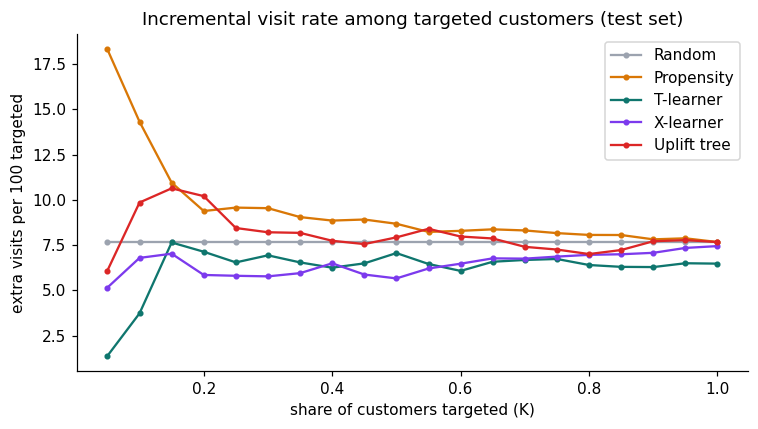

In [46]:
fig, ax = plt.subplots(figsize=(7, 4))
for name in STRATS:
    d = table[table.strategy == name]
    ax.plot(d.k, d.inc_visit_per_targeted * 100, marker="o", ms=3, label=name, color=COL[name])
ax.set_xlabel("share of customers targeted (K)"); ax.set_ylabel("extra visits per 100 targeted")
ax.set_title("Incremental visit rate among targeted customers (test set)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "04_policy_visit_rate.png", bbox_inches="tight"); plt.show()

### Is the uplift policy convincingly better? (paired bootstrap)
Difference in incremental outcome **per targeted customer** between two strategies on the same resamples. 'Random' = expected value of random targeting (the everyone estimate).

In [48]:
cmp_rows = []
for out in ("visit", "spend"):
    for k in (0.2, 0.3, 0.5):
        for a, b in [("T-learner", "Random"), ("T-learner", "Propensity"), ("X-learner", "T-learner"), ("Uplift tree", "Random"), ("Uplift tree", "Propensity")]:
            (sa, pa), (sb, pb) = STRATS[a], STRATS[b]
            d = bootstrap_policy_diff(s[out].to_numpy(), s.arm.to_numpy(), pa.to_numpy(), sa.to_numpy(), pb.to_numpy(), sb.to_numpy(),
                                      k, k_b=(1.0 if b == "Random" else k), n_boot=N_BOOT)
            cmp_rows.append({"outcome": out, "k": k, "comparison": f"{a} - {b}", **d})
policy_cmp = pd.DataFrame(cmp_rows)
policy_cmp["convincing"] = (policy_cmp.lo > 0) | (policy_cmp.hi < 0)
display(policy_cmp)

,outcome,k,comparison,diff,lo,hi,p_a_better,convincing
0,visit,0.2000,T-learner - Random,-0.0054,-0.0391,0.0265,0.3900,False
1,visit,0.2000,T-learner - Propensity,-0.0225,-0.0630,0.0203,0.1667,False
2,visit,0.2000,X-learner - T-learner,-0.0128,-0.0463,0.0159,0.2333,False
3,visit,0.2000,Uplift tree - Random,0.0253,-0.0191,0.0499,0.8000,False
4,visit,0.2000,Uplift tree - Propensity,0.0082,-0.0511,0.0411,0.4800,False
5,visit,0.3000,T-learner - Random,-0.0073,-0.0361,0.0210,0.3100,False
6,visit,0.3000,T-learner - Propensity,-0.0260,-0.0625,0.0111,0.0933,False
7,visit,0.3000,X-learner - T-learner,-0.0116,-0.0386,0.0088,0.1600,False
8,visit,0.3000,Uplift tree - Random,0.0054,-0.0079,0.0389,0.8633,False
9,visit,0.3000,Uplift tree - Propensity,-0.0133,-0.0356,0.0266,0.3800,False


### Does choosing the email *version* per customer add anything?
The uplift models pick, for each customer, the version with the larger estimated uplift. But if one version is at least as good as the other for *everyone*, that choice cannot add value. Test: the T-learner ranking with its chosen version vs the same ranking sending the **men's email to everyone targeted** (paired bootstrap, same resamples). We also report the two emails' effects inside the classic purchase-history segments (all test customers), which is what the models are implicitly learning.

In [52]:
ver_rows = []
ones = np.ones(len(s), dtype=int)
for k in (0.3, 0.5, 1.0):
    d = bootstrap_policy_diff(s.visit.to_numpy(), s.arm.to_numpy(), s.T_best_arm.to_numpy(), s.T_policy_score.to_numpy(),
                              ones, s.T_policy_score.to_numpy(), k, n_boot=N_BOOT)
    ver_rows.append({"k": k, "comparison": "T-learner chosen version - T-learner men's for all", **d})
version = pd.DataFrame(ver_rows); version["convincing"] = (version.lo > 0) | (version.hi < 0)
display(version)

seg_name = np.select([(s.mens == 1) & (s.womens == 0), (s.mens == 0) & (s.womens == 1)], ["men's only", "women's only"], "both lines")
seg_rows = []
for sname in ("men's only", "women's only", "both lines"):
    g = s[seg_name == sname]
    row = {"segment": sname, "share_of_customers": len(g) / len(s), "visit_rate_no_email": g.loc[g.arm == 0, "visit"].mean()}
    for arm in (1, 2):
        d = diff_in_means(g.loc[g.arm == arm, "visit"], g.loc[g.arm == 0, "visit"])
        row[f"uplift_{ARM_SHORT[arm]}"], row[f"uplift_{ARM_SHORT[arm]}_lo"], row[f"uplift_{ARM_SHORT[arm]}_hi"] = d["diff"], d["lo"], d["hi"]
    seg_rows.append(row)
segments = pd.DataFrame(seg_rows)
display(segments.set_index("segment").style.format("{:.3f}"))

,k,comparison,diff,lo,hi,p_a_better,convincing
0,0.3000,T-learner chosen version - T-learner men's for...,-0.0112,-0.0288,0.0068,0.1400,False
1,0.5000,T-learner chosen version - T-learner men's for...,-0.0152,-0.0317,-0.0014,0.0100,True
2,1.0000,T-learner chosen version - T-learner men's for...,-0.0119,-0.0206,-0.0032,0.0067,True


,share_of_customers,visit_rate_no_email,uplift_mens,uplift_mens_lo,uplift_mens_hi,uplift_womens,uplift_womens_lo,uplift_womens_hi
segment,,,,,,,,
men's only,0.448,0.097,0.071,0.050,0.093,0.015,-0.005,0.034
women's only,0.451,0.106,0.058,0.036,0.079,0.065,0.043,0.087
both lines,0.101,0.143,0.189,0.135,0.244,0.118,0.064,0.172


## 5. From visits to money: the visit-to-money bridge
The models were trained on visits. Did targeting their top customers also bring **extra purchases and spend**? We use the experiment directly: inside each strategy's top K%, compare conversion and spend of customers who got the recommended email vs no email. Spend is mostly zeros, so we rely on bootstrap CIs. This bridge uses no model of money at all.

,strategy,k,conversion,conversion_lo,conversion_hi,spend,spend_lo,spend_hi
0,Random,0.1000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937
1,Random,0.2000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937
2,Random,0.3000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937
3,Random,0.5000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937
4,Random,1.0000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937
5,Propensity,0.1000,0.0211,-0.0012,0.0399,2.7693,-0.4358,6.3515
6,Propensity,0.2000,0.0082,-0.0023,0.0211,0.9599,-0.5435,2.8140
7,Propensity,0.3000,0.0125,0.0016,0.0239,1.5070,0.1382,2.9773
8,Propensity,0.5000,0.0103,0.0038,0.0174,1.1389,-0.1047,2.3143
9,Propensity,1.0000,0.0066,0.0026,0.0107,0.7453,0.0844,1.3937


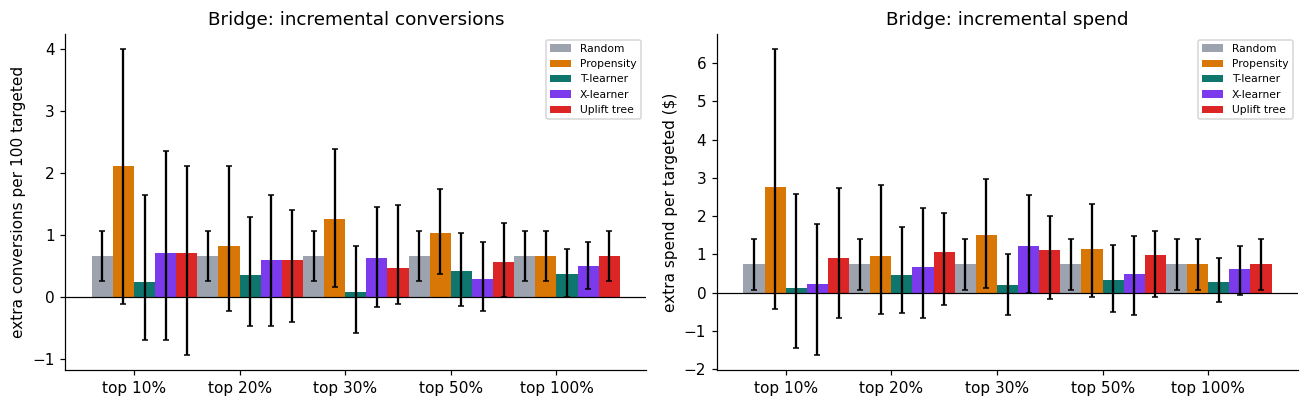

In [53]:
bridge = policy_ci[["strategy", "k", "conversion", "conversion_lo", "conversion_hi", "spend", "spend_lo", "spend_hi"]]
display(bridge)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, out, scale, lab in [(axes[0], "conversion", 100, "extra conversions per 100 targeted"), (axes[1], "spend", 1, "extra spend per targeted ($)")]:
    w = 0.2
    for i, name in enumerate(STRATS):
        d = policy_ci[policy_ci.strategy == name]
        x = np.arange(len(KS)) + (i - 1.5) * w
        ax.bar(x, d[out] * scale, width=w, color=COL[name], label=name,
               yerr=[(d[out] - d[out + "_lo"]) * scale, (d[out + "_hi"] - d[out]) * scale], capsize=2)
    ax.set_xticks(range(len(KS))); ax.set_xticklabels([f"top {int(k*100)}%" for k in KS]); ax.axhline(0, c="black", lw=.8)
    ax.set_ylabel(lab); ax.legend(fontsize=7)
axes[0].set_title("Bridge: incremental conversions"); axes[1].set_title("Bridge: incremental spend")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_bridge_money.png", bbox_inches="tight"); plt.show()

## 6. Sensitivity check: what if we had trained on conversion?
The conversion-trained T-learner (notebook 03) is compared with the visit-trained one: do they rank customers the same way, and which ranks **conversions** better on the test set?

In [56]:
rho = spearmanr(s.T_policy_score, s.Tconv_policy_score).statistic
top_v = set(s.T_policy_score.nlargest(int(.3 * len(s))).index); top_c = set(s.Tconv_policy_score.nlargest(int(.3 * len(s))).index)
overlap = len(top_v & top_c) / len(top_v)
same_email = (s.T_best_arm == s.Tconv_best_arm).mean()
print(f"Spearman rank correlation (policy scores): {rho:.3f}")
print(f"Overlap of top-30% lists: {overlap:.1%} (random lists would overlap ~30%)")
print(f"Same recommended email: {same_email:.1%}")
sens_rows = []
for arm in (1, 2):
    sub, y, t = arm_data(arm, "conversion")
    for name, col in [("T-learner (visit)", "T_uplift_{arm}"), ("T-learner (conversion)", "Tconv_uplift_{arm}"),
                      ("Propensity", "propensity"), ("Random", "random_score")]:
        b = bootstrap(qini_coefficient, y, t, sub[col.format(arm=ARM_SHORT[arm])].to_numpy(), n_boot=N_BOOT)
        sens_rows.append({"email": ARMS[arm], "model": name, "qini_on_conversion": b["estimate"], "lo": b["lo"], "hi": b["hi"]})
sens = pd.DataFrame(sens_rows)
display(sens)

Spearman rank correlation (policy scores): -0.023
Overlap of top-30% lists: 33.8% (random lists would overlap ~30%)
Same recommended email: 67.6%


,email,model,qini_on_conversion,lo,hi
0,Mens E-Mail,T-learner (visit),-0.0002,-0.0008,0.0004
1,Mens E-Mail,T-learner (conversion),0.0000,-0.0007,0.0007
2,Mens E-Mail,Propensity,0.0005,-0.0001,0.0011
3,Mens E-Mail,Random,-0.0002,-0.0009,0.0005
4,Womens E-Mail,T-learner (visit),0.0004,-0.0001,0.0011
5,Womens E-Mail,T-learner (conversion),0.0002,-0.0004,0.0007
6,Womens E-Mail,Propensity,0.0002,-0.0004,0.0007
7,Womens E-Mail,Random,0.0003,-0.0002,0.0008


## 7. Economics: when does targeting pay? (SCENARIO ASSUMPTIONS, not data)
The data has no costs or margins, so money needs assumptions. Two bridges from the experiment to money:
* **Visit-value bridge (main).** Value an incremental visit at the average spend per visitor observed in the *training* data, times the margin. Spend per visitor is similar in every arm (checked below), and the result is conservative: observed incremental spend is higher than incremental visits × value per visit. Profit = incremental visits × value × margin − cost × contacts. Much less noisy than spend inside subgroups.
* **Observed-spend check (section 7b).** Directly use incremental spend inside each targeted group. Honest but 99% of customers spend $0, so it is very noisy.

Defaults: cost **$0.15** per contact, margin **30%** (`src/config.py`). The key question is not "which strategy made the most money at $0.15" but **at which cost per contact does targeting beat mailing everyone?**

Spend per visitor (train): {'pooled': 7.02, 'Mens E-Mail': 7.36, 'No E-Mail': 6.32, 'Womens E-Mail': 7.09}
Value of one incremental visit at 30% margin: $2.11
Bridge check on the test set (per customer emailed): the bridge is conservative


,email,incremental visits x value,observed incremental spend
0,Mens E-Mail,0.5386,0.7453
1,Womens E-Mail,0.3186,0.2898


,strategy,k,n_contacted,inc_visits,campaign_cost,incremental_profit,break_even_cost,cost_per_inc_visit
0,Propensity,0.7000,"44,800.0000","3,724.9470","6,720.0000","1,122.0880",0.1750,1.8040
1,Random,1.0000,"64,000.0000","4,911.5230","9,600.0000",740.1720,0.1620,1.9550
2,T-learner,0.1500,"9,600.0000",734.3660,"1,440.0000",106.0520,0.1610,1.9610
3,Uplift tree,0.5500,"35,200.0000","2,958.5100","5,280.0000",948.5160,0.1770,1.7850
4,X-learner,1.0000,"64,000.0000","4,768.5250","9,600.0000",439.1190,0.1570,2.0130


Email everyone (men's): 4,912 extra visits, profit 740 $, break-even cost $0.162 per contact


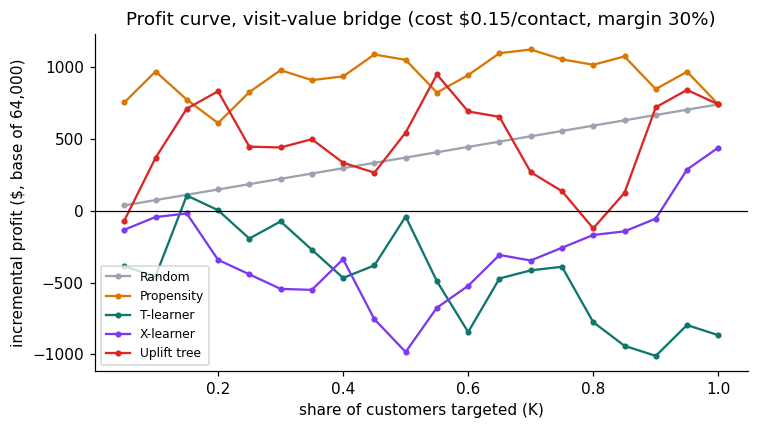

In [57]:
vpv = value_per_visit(train)
VALUE = vpv["pooled"]
print("Spend per visitor (train):", {k: round(v, 2) for k, v in vpv.items()})
print(f"Value of one incremental visit at {MARGIN_RATE:.0%} margin: ${VALUE * MARGIN_RATE:.2f}")
chk = []
for arm in (1, 2):
    sub, y, t = arm_data(arm)
    inc_v = y[t == 1].mean() - y[t == 0].mean(); inc_s = sub.spend[t == 1].mean() - sub.spend[t == 0].mean()
    chk.append({"email": ARMS[arm], "incremental visits x value": inc_v * VALUE, "observed incremental spend": inc_s})
print("Bridge check on the test set (per customer emailed): the bridge is conservative"); display(pd.DataFrame(chk))

econ_v = add_visit_economics(table, POP, VALUE, MARGIN_RATE, COST_PER_CONTACT)
best_v = econ_v.loc[econ_v.groupby("strategy")["incremental_profit"].idxmax(), ["strategy", "k", "n_contacted", "inc_visits", "campaign_cost", "incremental_profit", "break_even_cost", "cost_per_inc_visit"]].reset_index(drop=True)
display(best_v.round(3))
everyone_v = econ_v[(econ_v.strategy == "Random") & (econ_v.k == 1.0)].iloc[0]
print(f"Email everyone (men's): {everyone_v.inc_visits:,.0f} extra visits, profit {everyone_v.incremental_profit:,.0f} $, break-even cost ${everyone_v.break_even_cost:.3f} per contact")

fig, ax = plt.subplots(figsize=(7, 4))
for name in STRATS:
    d = econ_v[econ_v.strategy == name]
    ax.plot(d.k, d.incremental_profit, marker="o", ms=3, label=name, color=COL[name])
ax.axhline(0, c="black", lw=.8)
ax.set_xlabel("share of customers targeted (K)"); ax.set_ylabel("incremental profit ($, base of 64,000)")
ax.set_title(f"Profit curve, visit-value bridge (cost ${COST_PER_CONTACT}/contact, margin {MARGIN_RATE:.0%})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_profit_curve.png", bbox_inches="tight"); plt.show()

### Break-even cost and the decision map
For each strategy and share targeted, the **break-even cost per contact** is the cost at which the campaign stops paying: uplift in the group × value per visit × margin. Emailing everyone breaks even at the average effect; a good targeting rule raises the break-even for the customers it keeps. The decision map then shows, for a range of contact costs, the most profitable (strategy, share) and its gain over mailing everyone.

Break-even cost per contact ($) by strategy and share targeted


strategy,Propensity,Random,T-learner,Uplift tree,X-learner
k,,,,,
0.1000,0.3010,0.1620,0.0790,0.2080,0.1430
0.2000,0.1980,0.1620,0.1500,0.2150,0.1230
0.3000,0.2010,0.1620,0.1460,0.1730,0.1220
0.5000,0.1830,0.1620,0.1490,0.1670,0.1190
1.0000,0.1620,0.1620,0.1360,0.1620,0.1570


,cost_per_contact,best_strategy,best_k,best_profit,everyone_profit,gain_vs_everyone
0,0.0500,Uplift tree,1.0000,"7,140.0000","7,140.0000",0.0000
1,0.0750,Uplift tree,1.0000,"5,540.0000","5,540.0000",0.0000
2,0.1000,Propensity,0.9500,"4,007.0000","3,940.0000",67.0000
3,0.1250,Propensity,0.9500,"2,487.0000","2,340.0000",147.0000
4,0.1500,Propensity,0.7000,"1,122.0000",740.0000,382.0000
5,0.1750,Propensity,0.1000,809.0000,-860.0000,"1,669.0000"
6,0.2000,Propensity,0.1000,649.0000,"-2,460.0000","3,109.0000"
7,0.2250,Propensity,0.0500,513.0000,"-4,060.0000","4,573.0000"
8,0.2500,Propensity,0.0500,433.0000,"-5,660.0000","6,093.0000"
9,0.2750,Propensity,0.0500,353.0000,"-7,260.0000","7,613.0000"


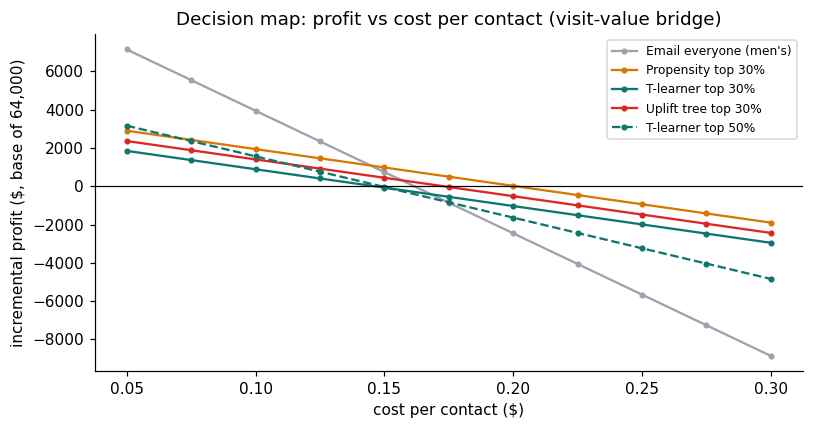

In [58]:
be = econ_v[econ_v.k.isin([0.1, 0.2, 0.3, 0.5, 1.0])].pivot(index="k", columns="strategy", values="break_even_cost")
print("Break-even cost per contact ($) by strategy and share targeted"); display(be.round(3))

COSTS = np.round(np.arange(0.05, 0.301, 0.025), 3)
dmap = decision_map(table, POP, VALUE, MARGIN_RATE, COSTS)
display(dmap.assign(best_profit=dmap.best_profit.round(0), everyone_profit=dmap.everyone_profit.round(0), gain_vs_everyone=dmap.gain_vs_everyone.round(0)))

fig, ax = plt.subplots(figsize=(7.5, 4))
lines = [("Random", 1.0, "Email everyone (men's)"), ("Propensity", 0.3, "Propensity top 30%"), ("T-learner", 0.3, "T-learner top 30%"),
         ("Uplift tree", 0.3, "Uplift tree top 30%"), ("T-learner", 0.5, "T-learner top 50%")]
for strat, k, lab in lines:
    r = table[(table.strategy == strat) & (table.k == k)].iloc[0]
    n = np.ceil(k * POP)
    prof = [r.inc_visit_per_targeted * n * VALUE * MARGIN_RATE - cc * n for cc in COSTS]
    ax.plot(COSTS, prof, marker="o", ms=3, label=lab, color=COL[strat], ls="-" if k != 0.5 else "--")
ax.axhline(0, c="black", lw=.8); ax.set_xlabel("cost per contact ($)"); ax.set_ylabel("incremental profit ($, base of 64,000)")
ax.set_title("Decision map: profit vs cost per contact (visit-value bridge)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_decision_map.png", bbox_inches="tight"); plt.show()

### A category campaign: the women's email on its own
Sometimes the business decides the *content* (a women's-collection launch) and the only question is **who** gets it. Here the uplift models shine: contacts, incremental visits, cost per incremental visit and profit for the women's email sent to everyone vs to the model's top 50%.

In [59]:
sub, y, t = arm_data(2)
wrows = []
ate_w = y[t == 1].mean() - y[t == 0].mean()
for name, k in [("Everyone", 1.0), ("Propensity", 0.5), ("T-learner", 0.5), ("Uplift tree", 0.5), ("Propensity", 0.3), ("T-learner", 0.3), ("Uplift tree", 0.3)]:
    u = ate_w if name == "Everyone" else uplift_at_k(y, t, sub[MODELS[name].format(arm="womens")].to_numpy(), k)
    n = k * POP
    wrows.append({"strategy": name, "share": k, "contacts": n, "inc_visits": u * n, "share_of_lift": (u * n) / (ate_w * POP),
                  "cost": COST_PER_CONTACT * n, "cost_per_inc_visit": COST_PER_CONTACT / u, "profit": u * n * VALUE * MARGIN_RATE - COST_PER_CONTACT * n})
womens_campaign = pd.DataFrame(wrows)
display(womens_campaign.round(2))

,strategy,share,contacts,inc_visits,share_of_lift,cost,cost_per_inc_visit,profit
0,Everyone,1.0000,"64,000.0000","2,905.2300",1.0000,"9,600.0000",3.3000,"-3,483.6500"
1,Propensity,0.5000,"32,000.0000","1,920.2900",0.6600,"4,800.0000",2.5000,-757.2300
2,T-learner,0.5000,"32,000.0000","2,355.5200",0.8100,"4,800.0000",2.0400,159.0500
3,Uplift tree,0.5000,"32,000.0000","2,446.7800",0.8400,"4,800.0000",1.9600,351.1800
4,Propensity,0.3000,"19,200.0000","1,257.5800",0.4300,"2,880.0000",2.2900,-232.4300
5,T-learner,0.3000,"19,200.0000","1,596.9400",0.5500,"2,880.0000",1.8000,482.0100
6,Uplift tree,0.3000,"19,200.0000","1,666.8500",0.5700,"2,880.0000",1.7300,629.2000


### 7b. Observed-spend check (no bridge, very noisy)
Same economics, but incremental spend measured directly inside each targeted group. Shown for honesty: the point estimates jump around and the CIs overlap, which is exactly why the visit-value bridge is the main view.

,strategy,k,n_contacted,campaign_cost,incremental_profit,inc_spend
0,Propensity,0.4000,"25,600.0000","3,840.0000","9,483.7005","44,412.3351"
1,Random,1.0000,"64,000.0000","9,600.0000","4,708.9791","47,696.5970"
2,T-learner,0.1500,"9,600.0000","1,440.0000",105.1471,"5,150.4905"
3,Uplift tree,0.6000,"38,400.0000","5,760.0000","8,706.5534","48,221.8446"
4,X-learner,0.2500,"16,000.0000","2,400.0000","4,531.0153","23,103.3842"


Target everyone with the men's email:


,inc_spend,campaign_cost,incremental_profit
19,"47,696.5970","9,600.0000","4,708.9791"


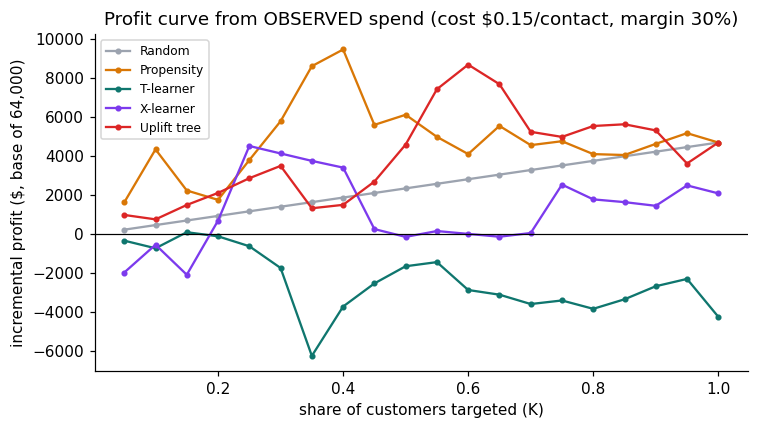

In [60]:
econ = add_economics(table, POP, COST_PER_CONTACT, MARGIN_RATE)
best = best_threshold(econ)
display(best)
everyone = econ[(econ.strategy == "Random") & (econ.k == 1.0)][["inc_spend", "campaign_cost", "incremental_profit"]]
print("Target everyone with the men's email:"); display(everyone)
fig, ax = plt.subplots(figsize=(7, 4))
for name in STRATS:
    d = econ[econ.strategy == name]
    ax.plot(d.k, d.incremental_profit, marker="o", ms=3, label=name, color=COL[name])
ax.axhline(0, c="black", lw=.8)
ax.set_xlabel("share of customers targeted (K)"); ax.set_ylabel("incremental profit ($, base of 64,000)")
ax.set_title(f"Profit curve from OBSERVED spend (cost ${COST_PER_CONTACT}/contact, margin {MARGIN_RATE:.0%})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_profit_curve_spend.png", bbox_inches="tight"); plt.show()

### How uncertain is the profit? (bootstrap at fixed K)
The spend estimate behind every profit number is noisy. Here is the 95% CI of incremental profit for each strategy at K = 20%, 30%, 50% and 100%.

In [61]:
prof_rows = []
for _, r in policy_ci.iterrows():
    n = np.ceil(r.k * POP)
    f = lambda s: s * n * MARGIN_RATE - COST_PER_CONTACT * n
    prof_rows.append({"strategy": r.strategy, "k": r.k, "profit": f(r.spend), "profit_lo": f(r.spend_lo), "profit_hi": f(r.spend_hi)})
profit_ci = pd.DataFrame(prof_rows)
display(profit_ci.pivot(index="k", columns="strategy", values="profit").round(0))
display(profit_ci[profit_ci.k.isin([0.3, 1.0])])

strategy,Propensity,Random,T-learner,Uplift tree,X-learner
k,,,,,
0.1000,"4,357.0000",471.0000,-719.0000,765.0000,-538.0000
0.2000,"1,766.0000",942.0000,-106.0000,"2,121.0000",700.0000
0.3000,"5,801.0000","1,413.0000","-1,730.0000","3,509.0000","4,147.0000"
0.5000,"6,134.0000","2,354.0000","-1,642.0000","4,604.0000",-135.0000
1.0000,"4,709.0000","4,709.0000","-4,236.0000","4,709.0000","2,099.0000"


,strategy,k,profit,profit_lo,profit_hi
2,Random,0.3000,"1,412.6937","-2,393.8329","5,147.6675"
4,Random,1.0000,"4,708.9791","-7,979.4429","17,158.8915"
7,Propensity,0.3000,"5,800.5989","-2,083.9581","14,269.4661"
9,Propensity,1.0000,"4,708.9791","-7,979.4429","17,158.8915"
12,T-learner,0.3000,"-1,730.1125","-6,195.8954","2,926.5578"
14,T-learner,1.0000,"-4,236.1540","-14,397.3190","7,772.2626"
17,X-learner,0.3000,"4,147.4433","-2,954.1922","11,792.1040"
19,X-learner,1.0000,"2,099.0995","-10,790.2433","13,765.2494"
22,Uplift tree,0.3000,"3,509.3058","-3,823.3414","8,611.3487"
24,Uplift tree,1.0000,"4,708.9791","-7,979.4429","17,158.8915"


### Sensitivity to the cost assumption
Best K and profit for each strategy when the cost per contact changes (margin stays 30%).

In [62]:
sens_cost = []
for c in COST_GRID:
    b = best_threshold(add_economics(table, POP, c, MARGIN_RATE))
    for _, r in b.iterrows():
        sens_cost.append({"cost_per_contact": c, "strategy": r.strategy, "best_k": r.k, "profit_at_best_k": r.incremental_profit})
sens_cost = pd.DataFrame(sens_cost)
display(sens_cost.pivot(index="cost_per_contact", columns="strategy", values="profit_at_best_k").round(0))
display(sens_cost.pivot(index="cost_per_contact", columns="strategy", values="best_k"))

strategy,Propensity,Random,T-learner,Uplift tree,X-learner
cost_per_contact,,,,,
0.0500,"12,044.0000","11,109.0000","3,788.0000","12,547.0000","8,588.0000"
0.1500,"9,484.0000","4,709.0000",105.0000,"8,707.0000","4,531.0000"
0.3000,"5,644.0000",0.0000,0.0000,"2,947.0000","2,131.0000"
0.5000,"2,117.0000",0.0000,0.0000,0.0000,0.0000


strategy,Propensity,Random,T-learner,Uplift tree,X-learner
cost_per_contact,,,,,
0.0500,0.4000,1.0000,0.9500,0.6000,0.9500
0.1500,0.4000,1.0000,0.1500,0.6000,0.2500
0.3000,0.4000,0.0000,0.0000,0.6000,0.2500
0.5000,0.1000,0.0000,0.0000,0.0000,0.0000


In [63]:
table.to_csv(RESULTS_DIR / "04_strategy_table.csv", index=False)
save_json({"ranking": rank.to_dict("records"), "paired": paired.to_dict("records"), "lift_captured": lift.to_dict("records"),
           "deciles": {ARM_SHORT[a]: dec[a].to_dict("records") for a in (1, 2)}, "sleeping_dog_evidence": sleeping,
           "tree_leaves_womens_test": leaf_tab.reset_index().to_dict("records"),
           "policy_ci": policy_ci.to_dict("records"), "policy_cmp": policy_cmp.to_dict("records"),
           "version_choice": version.to_dict("records"), "segments": segments.to_dict("records"),
           "sensitivity": {"spearman": rho, "top30_overlap": overlap, "same_email": same_email, "qini_conversion": sens.to_dict("records")},
           "economics": {"population": POP, "cost": COST_PER_CONTACT, "margin": MARGIN_RATE,
                         "best": best.to_dict("records"), "everyone": everyone.to_dict("records"),
                         "profit_ci": profit_ci.to_dict("records"), "cost_sensitivity": sens_cost.to_dict("records")},
           "economics_visit": {"value_per_visit": vpv, "value": VALUE, "bridge_check": chk, "best": best_v.to_dict("records"),
                               "everyone": {k: float(everyone_v[k]) for k in ("inc_visits", "campaign_cost", "incremental_profit", "break_even_cost", "cost_per_inc_visit")},
                               "break_even": be.reset_index().to_dict("records"), "decision_map": dmap.to_dict("records"),
                               "womens_campaign": womens_campaign.to_dict("records")}},
          "04_evaluation.json")
print("saved")

saved


# What We Found (Honest Summary)

## 1. Ranking customers for each email

**Women's email: uplift models identify customers with potentially stronger responses.**

On the held-out test set of 12,800 customers, uplift models achieved higher Qini point estimates than the propensity baseline. The T-Learner, X-Learner, S-Learner, and uplift tree all showed evidence of useful treatment-effect ranking, although individual model comparisons remain subject to sampling uncertainty.

The results suggest that the women's email is particularly effective among customers with a history of purchasing women's merchandise. Targeting these customers can capture a larger proportion of the email's incremental visits while contacting fewer customers.

**Men's email:** The men's email has a strong positive average effect, but the uplift models do not demonstrate a consistent ranking advantage over the propensity baseline. Its effect appears more broadly distributed across customer groups.

**Sleeping dogs:** We found no statistically convincing evidence of customer groups whose visit probability is reduced by receiving either email. This does not prove that negative individual treatment effects are impossible.

## 2. The whole campaign: whom to contact and which email to send

Strong performance when ranking customers for one specific email does not automatically translate into a better overall campaign that chooses between both email versions.

The evaluation indicates that the uplift models' advantage in women's-email ranking does not reliably translate into superior whole-campaign performance.

The men's email remains a strong default because it produces a substantial average increase in visits across customer segments.

Choosing the email version separately for every customer also does not necessarily improve performance. In the held-out evaluation, the T-Learner's personalized email selection performed worse than sending the men's email under the same targeting approach at full coverage.

**Interpretation:** Predicting individual treatment effects is useful, but optimizing a campaign requires evaluating the complete decision policy, including who receives an email, which email they receive, and how many customers are contacted.

## 3. Economics: validation-selected strategies evaluated on unseen test data

**Scenario assumptions:**
- Customer population: 64,000
- Cost per email contact: $0.15
- Average spending value assigned to an incremental visit: $7.02
- Assumed profit margin: 30%

The economic calculation is:

**Incremental profit = Estimated incremental visits × $7.02 × 30% − Number of contacts × $0.15**

These are scenario estimates, not directly observed profits.

### Avoiding test-set optimization bias

To avoid selecting the most profitable targeting percentage using the same test data used for evaluation, we adopted a train–validation–test procedure.

The model-training process uses the training data. The targeting percentage (K) is selected using validation data. The selected percentage is then fixed and evaluated on the held-out test set.

This provides a more defensible assessment than selecting the best-performing K directly from test-set results.

### Targeting percentages selected on validation data

| Strategy | Selected share |
|---|---:|
| Propensity | 85% |
| Random | 100% |
| T-Learner | 90% |
| Uplift tree | 100% |
| X-Learner | 100% |

### Final test-set economic results

| Strategy | Selected share | Estimated incremental profit |
|---|---:|---:|
| Propensity | 85% | $1,073 |
| Random | 100% | $740 |
| T-Learner | 90% | −$1,010 |
| Uplift tree | 100% | $740 |
| X-Learner | 100% | $439 |

Under these assumptions, **Propensity has the highest estimated profit among the evaluated validation-selected strategies**.

However, point estimates alone do not establish a statistically reliable advantage.

### Paired bootstrap comparison of estimated profits

Comparing Propensity with the other strategies:

| Comparison | Estimated difference | 95% confidence interval | Statistically convincing? |
|---|---:|---:|---|
| Propensity − Random | +$333 | [−$277, +$888] | No |
| Propensity − T-Learner | +$2,083 | [+$715, +$3,393] | Yes |
| Propensity − Uplift tree | +$333 | [−$206, +$800] | No |
| Propensity − X-Learner | +$634 | [−$329, +$1,773] | No |

The propensity baseline significantly outperforms the T-Learner under the evaluated scenario and bootstrap procedure.

However, its estimated advantages over Random, X-Learner, and the uplift tree are not statistically convincing because their confidence intervals include zero.

**Important limitation:** The economic findings depend on the assumed value of incremental visits, profit margin, and contact cost. Observed customer spending is sparse and noisy, so these results should not be interpreted as guaranteed future financial outcomes.

## 4. Final conclusion

The project demonstrates that **uplift modeling can identify differences in customer responsiveness to email promotions**, particularly for the women's merchandise campaign.

However, **better uplift ranking does not automatically lead to higher overall campaign profit**.

For this dataset, the propensity baseline remains highly competitive. After selecting targeting percentages on validation data and evaluating the resulting strategies on the held-out test set, Propensity achieves the highest estimated profit among the evaluated strategies.

Its advantage is statistically convincing against the T-Learner, but not against Random, the uplift tree, or the X-Learner.

The key marketing insight is that **the best targeting approach depends on the objective, the treatment, the campaign costs, and the reliability of estimated incremental effects**.

**Practical recommendation:** Use uplift models to identify potentially responsive customer segments, but compare the complete targeting strategies against simple baselines using randomized evidence and realistic financial assumptions before deployment. A more complex causal model should be adopted only when it demonstrates meaningful incremental business value.